# neuroinsight-ai — analysis walkthrough

This notebook walks through the evaluation pipeline in [`generate_clean_assets.py`](../generate_clean_assets.py) step by step. It imports the script's functions rather than re-implementing them, so every number below is produced by the same code that generates the README's §8 table and figures.

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Run from the repo root so the script's relative paths (data/, assets/) resolve.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# sklearn 1.9 deprecates SVC(probability=True); the script keeps it so results stay unchanged.
warnings.filterwarnings('ignore', category=FutureWarning)

import generate_clean_assets as g

## 1. Dataset

UCI Oxford Parkinson's Disease Detection dataset (Little et al.). Each row is one voice recording; several recordings come from the same subject, and the subject ID is embedded in the `name` column (`phon_R01_S01_1` → `S01`). That subject ID is what the cross-validation groups on — it is never used as a feature.

In [2]:
df, X, y, groups = g.load_data()

subjects = pd.DataFrame({'subject': groups, 'status': y})
per_subject = subjects.groupby('subject')['status'].agg(['size', 'nunique', 'first'])
assert (per_subject['nunique'] == 1).all(), 'a subject has mixed labels'

print(f"Recordings: {len(df)}")
print(f"Subjects:   {subjects['subject'].nunique()}")
print(f"Recordings per subject: min {per_subject['size'].min()}, max {per_subject['size'].max()}")
print(f"Features fed to the models: {X.shape[1]} (22 raw acoustic + VIC)")
print()
print("Class balance (recordings):", {k: int(v) for k, v in pd.Series(y).map({1: 'PD', 0: 'healthy'}).value_counts().items()})
print("Class balance (subjects):  ", {k: int(v) for k, v in per_subject['first'].map({1: 'PD', 0: 'healthy'}).value_counts().items()})
print(f"Majority class share (recordings): {y.mean():.3f}")

Recordings: 195
Subjects:   32
Recordings per subject: min 6, max 7
Features fed to the models: 23 (22 raw acoustic + VIC)

Class balance (recordings): {'PD': 147, 'healthy': 48}
Class balance (subjects):   {'PD': 24, 'healthy': 8}
Majority class share (recordings): 0.754


In [3]:
df[['name', 'status']].assign(subject=groups).head(8)

,name,status,subject
0,phon_R01_S01_1,1,S01
1,phon_R01_S01_2,1,S01
2,phon_R01_S01_3,1,S01
3,phon_R01_S01_4,1,S01
4,phon_R01_S01_5,1,S01
5,phon_R01_S01_6,1,S01
6,phon_R01_S02_1,1,S02
7,phon_R01_S02_2,1,S02


## 2. Vocal Instability Compound (VIC)

$$\text{VIC} = \log_{10}(\text{Jitter\%} \times \text{Shimmer:APQ3} \times \text{spread2} \times 1000)$$

Frequency micro-instability × amplitude micro-instability × frequency spread, combined as a log-product. `load_data()` computes it and appends it to the feature matrix, so all five models see it. Derivation and single-feature validation: [`docs/INDEX_PROPOSAL.md`](../docs/INDEX_PROPOSAL.md).

In [4]:
vic_check = np.log10(df['MDVP:Jitter(%)'] * df['Shimmer:APQ3'] * df['spread2'] * 1000)
assert np.allclose(df['VIC'], vic_check)
assert 'VIC' in X.columns

df.groupby(df['status'].map({1: 'PD', 0: 'healthy'}))['VIC'].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
status,,,,,,,,
PD,147.0,-1.690,0.535,-2.937,-2.047,-1.655,-1.387,-0.102
healthy,48.0,-2.357,0.451,-3.852,-2.645,-2.324,-1.971,-1.563


## 3. Cross-validation: 5-fold subject-grouped, 10 seeds

`StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)` for seeds 0–9, so 50 folds per model. All recordings from a subject land on the same side of every split — the model is never scored on a subject it trained on. With only ~6 subjects per validation fold, a single split is noisy, which is why results are averaged over 10 seeds.

Fold composition for one seed:

In [5]:
from sklearn.model_selection import StratifiedGroupKFold

skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
rows = []
for k, (tr, va) in enumerate(skf.split(X, y, groups=groups)):
    assert set(groups[tr]).isdisjoint(groups[va])
    rows.append({'fold': k, 'val subjects': len(set(groups[va])), 'val recordings': len(va),
                 'val PD share': round(y[va].mean(), 3)})
pd.DataFrame(rows)

,fold,val subjects,val recordings,val PD share
0,0,6,37,0.838
1,1,6,37,0.838
2,2,6,37,0.676
3,3,7,42,0.714
4,4,7,42,0.714


Now the full run — 5 models × 10 seeds × 5 folds, plus the majority-class baseline (always predict PD) over the same 50 folds:

In [6]:
t0 = time.time()
metrics_summary, oof_probabilities, seed_diagnostics, fold_degeneracy = g.run_cv(X, y, groups)
baseline_row = g.majority_baseline(X, y, groups)
res_df = pd.DataFrame(metrics_summary)
print(f"{len(g.models_config) * 50} fits in {time.time() - t0:.1f}s")

250 fits in 16.3s


## 4. Metrics

± is the std over the 50 folds, except AUC, which is the mean ± std of the 10 per-seed AUCs (each computed from that seed's out-of-fold probabilities). Same layout as README §8.

In [7]:
def pm(mean, std):
    return f"{mean:.3f} ± {std:.3f}"

table_rows = [baseline_row] + metrics_summary
table = pd.DataFrame({
    'Model': [r['Model'] for r in table_rows],
    'Accuracy': [pm(r['Accuracy'], r['Accuracy_std']) for r in table_rows],
    'Precision': [pm(r['Precision'], r['Precision_std']) for r in table_rows],
    'Recall': [pm(r['Recall'], r['Recall_std']) for r in table_rows],
    'F1-score': [pm(r['F1-score'], r['F1-score_std']) for r in table_rows],
    'AUC': ['—' if pd.isna(r['AUC_seed_mean']) else pm(r['AUC_seed_mean'], r['AUC_seed_std']) for r in table_rows],
})
md_lines = ['| ' + ' | '.join(table.columns) + ' |', '| :--- |' + ' :---: |' * (len(table.columns) - 1)]
md_lines += ['| ' + ' | '.join(row) + ' |' for row in table.itertuples(index=False)]
display(Markdown('\n'.join(md_lines)))

| Model | Accuracy | Precision | Recall | F1-score | AUC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Majority baseline (predict all-PD) | 0.756 ± 0.067 | 0.756 ± 0.067 | 1.000 ± 0.000 | 0.860 ± 0.043 | — |
| XGBoost | 0.796 ± 0.098 | 0.833 ± 0.093 | 0.924 ± 0.077 | 0.872 ± 0.063 | 0.741 ± 0.034 |
| Random Forest | 0.766 ± 0.095 | 0.818 ± 0.094 | 0.902 ± 0.097 | 0.852 ± 0.064 | 0.764 ± 0.022 |
| SVM | 0.792 ± 0.091 | 0.816 ± 0.085 | 0.945 ± 0.092 | 0.871 ± 0.063 | 0.636 ± 0.033 |
| Decision Tree | 0.730 ± 0.095 | 0.818 ± 0.088 | 0.839 ± 0.106 | 0.823 ± 0.067 | 0.637 ± 0.052 |
| KNN | 0.754 ± 0.081 | 0.810 ± 0.080 | 0.891 ± 0.086 | 0.844 ± 0.055 | 0.715 ± 0.046 |

Check against the table committed in README §8:

In [8]:
readme = (ROOT / 'README.md').read_text().splitlines()
start = next(i for i, l in enumerate(readme) if l.startswith('| Model | Accuracy'))
readme_rows = []
for line in readme[start + 2:]:
    if not line.startswith('|'):
        break
    readme_rows.append([c.strip().strip('*') for c in line.strip('|').split('|')])
readme_table = pd.DataFrame(readme_rows, columns=table.columns)

assert readme_table.equals(table), 'notebook table differs from README §8'
print('Matches README §8 exactly.')

Matches README §8 exactly.


Seed-level spread (how much the 10 per-seed means vary) is much tighter than fold-level spread; the script prints both:

In [9]:
print(g.format_metrics_table(baseline_row, res_df).to_string(index=False))

                             Model                         Accuracy                        Precision                           Recall                         F1-score
Majority baseline (predict all-PD)                  0.756 +/- 0.067                  0.756 +/- 0.067                  1.000 +/- 0.000                  0.860 +/- 0.043
                           XGBoost 0.796 +/- 0.098 (seed +/- 0.024) 0.833 +/- 0.093 (seed +/- 0.017) 0.924 +/- 0.077 (seed +/- 0.021) 0.872 +/- 0.063 (seed +/- 0.016)
                     Random Forest 0.766 +/- 0.095 (seed +/- 0.016) 0.818 +/- 0.094 (seed +/- 0.010) 0.902 +/- 0.097 (seed +/- 0.020) 0.852 +/- 0.064 (seed +/- 0.013)
                               SVM 0.792 +/- 0.091 (seed +/- 0.017) 0.816 +/- 0.085 (seed +/- 0.012) 0.945 +/- 0.092 (seed +/- 0.023) 0.871 +/- 0.063 (seed +/- 0.014)
                     Decision Tree 0.730 +/- 0.095 (seed +/- 0.029) 0.818 +/- 0.088 (seed +/- 0.021) 0.839 +/- 0.106 (seed +/- 0.028) 0.823 +/- 0.067 (seed +/- 0.019

## 5. Figures

Bar chart of fold-averaged metrics with the majority baseline as dashed reference lines, then ROC / precision-recall curves. The curves use out-of-fold probabilities averaged across the 10 seeds, so their legend AUCs differ from the per-seed means in the table (notably Decision Tree: 0.723 on the curve vs 0.637 per-seed).

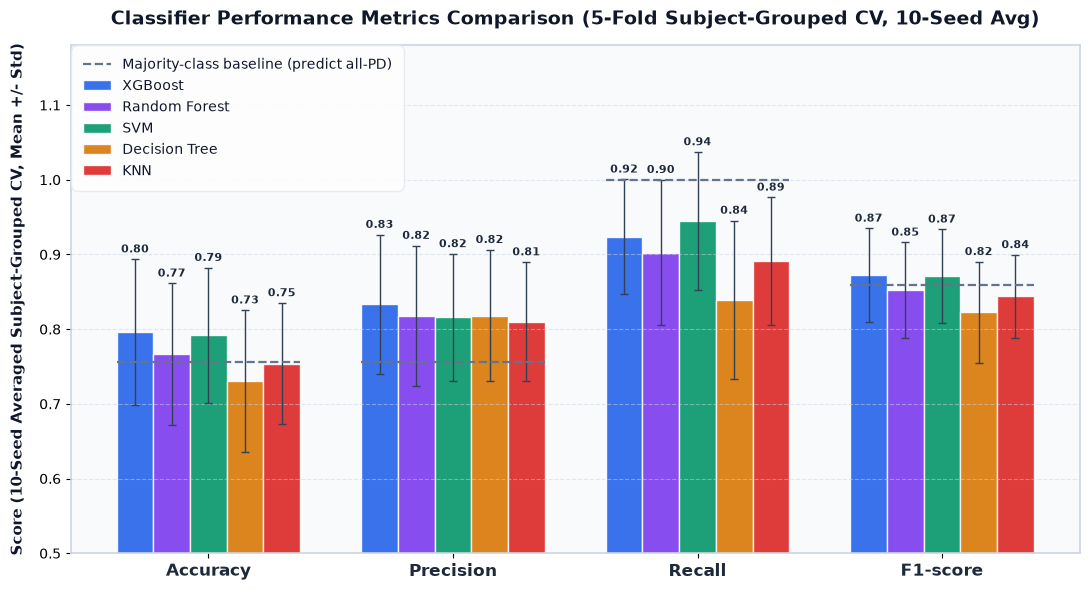

In [10]:
fig = g.plot_model_metrics(res_df, baseline_row)
fig.set_dpi(100)
plt.show()

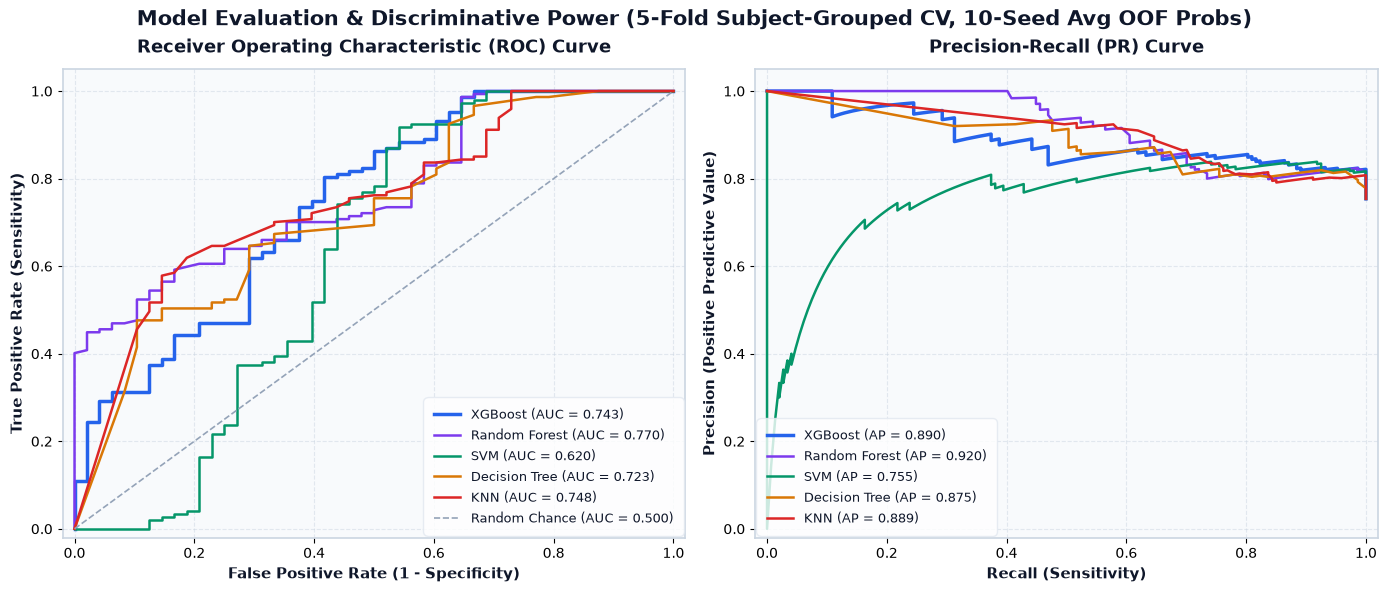

In [11]:
fig = g.plot_roc_pr(y, oof_probabilities)
fig.set_dpi(100)
plt.show()

Interpretation of these numbers (why XGBoost is the one to build on, why SVM's F1 is not evidence of signal) is in README §10.